In [2]:
from google.colab import files
uploaded = files.upload()


Saving Titanic-Dataset.csv to Titanic-Dataset.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import os
print(os.listdir())

['.config', 'Titanic-Dataset.csv', 'sample_data']


In [5]:
df=pd.read_csv("Titanic-Dataset.csv")

print("Dataset loaded successfully")

Dataset loaded successfully


In [6]:
df=pd.read_csv("Titanic-Dataset.csv")

In [7]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [9]:
print("Number of rows:",df.shape[0])
print("Number of columns:",df.shape[1])

Number of rows: 891
Number of columns: 12


In [10]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [11]:
print("Dataset Description:")
print("This dataset contains",
  df.shape[0], "rows and",
      df.shape[1],"columns.")
print("\nColumns names:")
print(list(df.columns))

Dataset Description:
This dataset contains 891 rows and 12 columns.

Columns names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [13]:

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))


Numerical Columns:
['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

Categorical Columns:
['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


In [14]:

df.describe()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [15]:

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)


Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [16]:

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

missing_report



,Missing Values,Missing Percentage
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
Age,177,19.865320
SibSp,0,0.000000
Parch,0,0.000000
Ticket,0,0.000000
Fare,0,0.000000


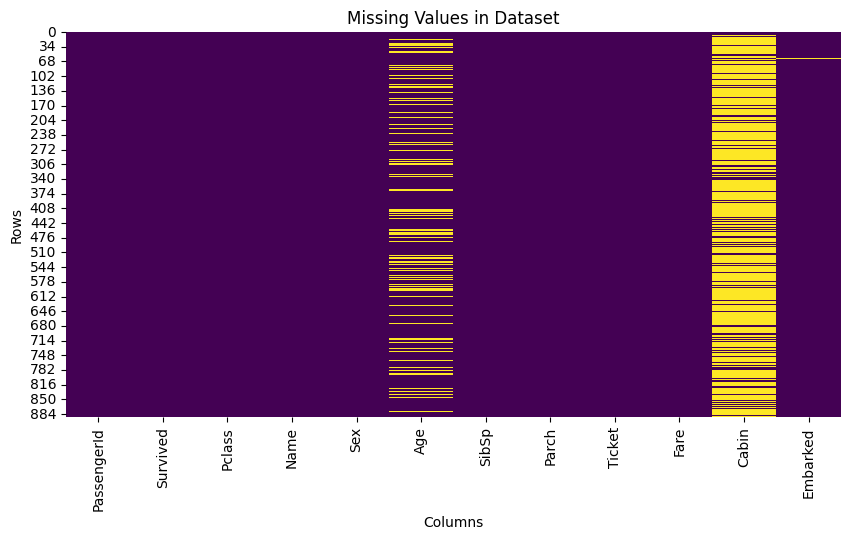

In [17]:

plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values in Dataset")
plt.xlabel("Columns")
plt.ylabel("Rows")

plt.show()


In [18]:

df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Copied dataset shape:", df_clean.shape)


Original dataset shape: (891, 12)
Copied dataset shape: (891, 12)


In [19]:

numerical_columns = df_clean.select_dtypes(
    include=np.number
).columns

for column in numerical_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

print("Missing numerical values handled.")


Missing numerical values handled.


In [20]:

categorical_columns = df_clean.select_dtypes(
    include=["object", "category", "bool"]
).columns

for column in categorical_columns:
    if df_clean[column].isnull().any():
        mode_value = df_clean[column].mode()

        if not mode_value.empty:
            df_clean[column] = df_clean[column].fillna(
                mode_value[0]
            )

print("Missing categorical values handled.")


Missing categorical values handled.


In [21]:

print("Missing values after cleaning:")
print(df_clean.isnull().sum())


Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


In [22]:

duplicate_count = df_clean.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


In [23]:

df_clean = df_clean.drop_duplicates()

print("Duplicate records removed.")
print("Dataset shape after removing duplicates:",
      df_clean.shape)


Duplicate records removed.
Dataset shape after removing duplicates: (891, 12)


In [24]:

print("Remaining duplicate rows:",
      df_clean.duplicated().sum())


Remaining duplicate rows: 0


In [25]:

df_clean.describe()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [26]:

if len(categorical_columns) > 0:
    column = categorical_columns[0]

    print("Frequency Counts for:", column)
    print(df_clean[column].value_counts())
else:
    print("No categorical columns found.")


Frequency Counts for: Name
Name
Braund, Mr. Owen Harris                                1
Cumings, Mrs. John Bradley (Florence Briggs Thayer)    1
Heikkinen, Miss. Laina                                 1
Futrelle, Mrs. Jacques Heath (Lily May Peel)           1
Allen, Mr. William Henry                               1
                                                      ..
Montvila, Rev. Juozas                                  1
Graham, Miss. Margaret Edith                           1
Johnston, Miss. Catherine Helen "Carrie"               1
Behr, Mr. Karl Howell                                  1
Dooley, Mr. Patrick                                    1
Name: count, Length: 891, dtype: int64


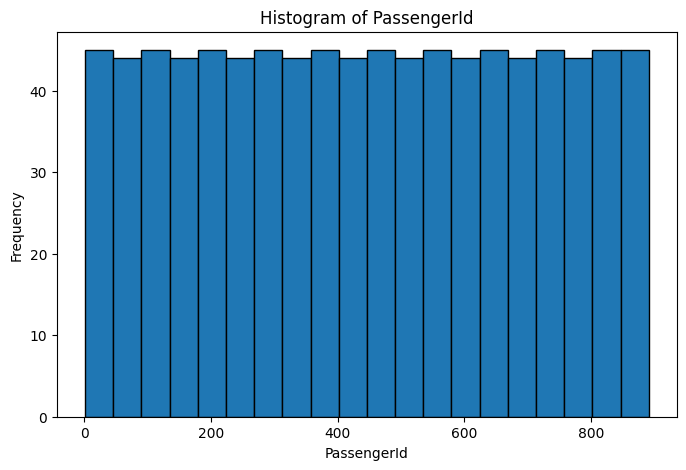

In [27]:

if len(numerical_columns) > 0:
    column = numerical_columns[0]

    plt.figure(figsize=(8, 5))

    plt.hist(
        df_clean[column],
        bins=20,
        edgecolor="black"
    )

    plt.title("Histogram of " + column)
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.show()


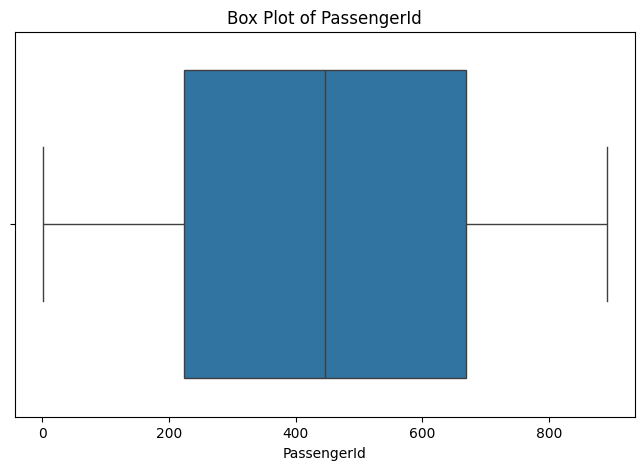

In [28]:

if len(numerical_columns) > 0:
    column = numerical_columns[0]

    plt.figure(figsize=(8, 5))

    sns.boxplot(x=df_clean[column])

    plt.title("Box Plot of " + column)
    plt.xlabel(column)

    plt.show()


In [29]:

print("Categorical Columns:")
print(list(categorical_columns))


Categorical Columns:
['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


In [30]:

df_encoded = pd.get_dummies(
    df_clean,
    columns=list(categorical_columns),
    drop_first=False,
    dtype=int
)

print("Dataset after encoding:")
df_encoded.head()


Dataset after encoding:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,"Name_Abbing, Mr. Anthony","Name_Abbott, Mr. Rossmore Edward","Name_Abbott, Mrs. Stanton (Rosa Hunt)",...,Cabin_F G73,Cabin_F2,Cabin_F33,Cabin_F38,Cabin_F4,Cabin_G6,Cabin_T,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,22.0,1,0,7.2500,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,2,1,1,38.0,1,0,71.2833,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,1,3,26.0,0,0,7.9250,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,4,1,1,35.0,1,0,53.1000,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,5,0,3,35.0,0,0,8.0500,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [31]:

print("Before Encoding:", df_clean.shape)
print("After Encoding:", df_encoded.shape)


Before Encoding: (891, 12)
After Encoding: (891, 1731)


In [32]:

df_scaled = df_encoded.copy()

# Identify numerical columns after encoding
scale_columns = df_scaled.select_dtypes(
    include=np.number
).columns.tolist()

# Standardize numerical columns
scaler = StandardScaler()

df_scaled[scale_columns] = scaler.fit_transform(
    df_scaled[scale_columns]
)

print("Numerical features scaled successfully.")


Numerical features scaled successfully.


In [33]:

df_scaled.head()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,"Name_Abbing, Mr. Anthony","Name_Abbott, Mr. Rossmore Edward","Name_Abbott, Mrs. Stanton (Rosa Hunt)",...,Cabin_F G73,Cabin_F2,Cabin_F33,Cabin_F38,Cabin_F4,Cabin_G6,Cabin_T,Embarked_C,Embarked_Q,Embarked_S
0,-1.730108,-0.789272,0.827377,-0.565736,0.432793,-0.473674,-0.502445,-0.03352,-0.03352,-0.03352,...,-0.047431,-0.058124,-0.058124,-0.03352,-0.047431,-0.067153,-0.03352,-0.482043,-0.307562,0.615838
1,-1.726220,1.266990,-1.566107,0.663861,0.432793,-0.473674,0.786845,-0.03352,-0.03352,-0.03352,...,-0.047431,-0.058124,-0.058124,-0.03352,-0.047431,-0.067153,-0.03352,2.074505,-0.307562,-1.623803
2,-1.722332,1.266990,0.827377,-0.258337,-0.474545,-0.473674,-0.488854,-0.03352,-0.03352,-0.03352,...,-0.047431,-0.058124,-0.058124,-0.03352,-0.047431,-0.067153,-0.03352,-0.482043,-0.307562,0.615838
3,-1.718444,1.266990,-1.566107,0.433312,0.432793,-0.473674,0.420730,-0.03352,-0.03352,-0.03352,...,-0.047431,-0.058124,-0.058124,-0.03352,-0.047431,-0.067153,-0.03352,-0.482043,-0.307562,0.615838
4,-1.714556,-0.789272,0.827377,0.433312,-0.474545,-0.473674,-0.486337,-0.03352,-0.03352,-0.03352,...,-0.047431,-0.058124,-0.058124,-0.03352,-0.047431,-0.067153,-0.03352,-0.482043,-0.307562,0.615838


In [34]:

print("Final Dataset Shape:", df_scaled.shape)

print("\nMissing Values:")
print(df_scaled.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df_scaled.duplicated().sum())


Final Dataset Shape: (891, 1731)

Missing Values:
0

Duplicate Rows:
0


In [35]:

output_file = "prepared_dataset.csv"

df_scaled.to_csv(
    output_file,
    index=False
)

print("Dataset saved successfully as:",
      output_file)


Dataset saved successfully as: prepared_dataset.csv


In [36]:

from google.colab import files

files.download("Titanic-Dataset.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>